In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models

DATA_CANDIDATES = [
    Path("data/komdigi_hoaks.csv"),
    Path("../../data/komdigi_hoaks.csv"),
    Path("../../../data/komdigi_hoaks.csv"),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("File data/komdigi_hoaks.csv tidak ditemukan.")

RANDOM_STATE = 42

In [2]:
# Muat teks artikel dan topik dari dataset Komdigi
data = pd.read_csv(DATA_PATH, usecols=["title", "body_text", "topics"])
data["text"] = data["title"].fillna("") + " " + data["body_text"].fillna("")
data["topics"] = data["topics"].fillna("").str.strip()
data = data.loc[data["text"].str.strip().ne("") & data["topics"].ne("")].copy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data["topics"])
class_ids = np.arange(len(label_encoder.classes_))

# Pisahkan data secara stratifikasi agar proporsi topik tetap terjaga.
X_train_val_text, X_test_text, y_train_val, y_test = train_test_split(
    data["text"], y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_train_val_text, y_train_val, test_size=0.125,
    random_state=RANDOM_STATE, stratify=y_train_val
)

# TF-IDF hanya di-fit pada data latih untuk mencegah kebocoran data.
vectorizer = TfidfVectorizer(max_features=512, ngram_range=(1, 2), min_df=2)
X_train = vectorizer.fit_transform(X_train_text).toarray().astype(np.float32)
X_val = vectorizer.transform(X_val_text).toarray().astype(np.float32)
X_test = vectorizer.transform(X_test_text).toarray().astype(np.float32)

class_weight_values = compute_class_weight(
    class_weight="balanced", classes=class_ids, y=y_train
)
class_weights = dict(zip(class_ids, class_weight_values))

print(f"Jumlah data: {len(data)}")
print(f"Training: {len(X_train)} | Validasi: {len(X_val)} | Testing: {len(X_test)}")
print("Kelas topik:", list(label_encoder.classes_))
print("Jumlah fitur TF-IDF:", X_train.shape[1])

Jumlah data: 4176
Training: 2922 | Validasi: 418 | Testing: 836
Kelas topik: ['Hoaks', 'Kesehatan', 'Masyarakat Digital', 'Pejabat Publik', 'Penipuan', 'Program/Kebijakan']
Jumlah fitur TF-IDF: 512


In [3]:
# Distribusi topik pada keseluruhan dataset
print(data["topics"].value_counts().to_string())

topics
Hoaks                 3534
Penipuan               288
Pejabat Publik         137
Masyarakat Digital     102
Program/Kebijakan       59
Kesehatan               56


In [4]:
# Jaringan dense digunakan untuk klasifikasi fitur teks TF-IDF
tf.keras.utils.set_random_seed(RANDOM_STATE)
model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(len(label_encoder.classes_), activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,310 (290.27 KB)

 Trainable params: 74,310 (290.27 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.2057 - loss: 1.6873 - val_accuracy: 0.3947 - val_loss: 1.5919
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3604 - loss: 1.2082 - val_accuracy: 0.5407 - val_loss: 1.3277
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4391 - loss: 0.8902 - val_accuracy: 0.5191 - val_loss: 1.2018
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5185 - loss: 0.6983 - val_accuracy: 0.5287 - val_loss: 1.1375
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5606 - loss: 0.5557 - val_accuracy: 0.5861 - val_loss: 1.0473
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6116 - loss: 0.4560 - val_accuracy: 0.6077 - val_loss: 0.9931
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6557 - loss: 0.3747 - val_accuracy: 0.6220 - val_loss: 1.0049
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6804 - loss: 0.3204 - val_accuracy: 0.6483 - val_loss

In [7]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Macro-F1      : {macro_f1:.4f}")
print("\nLaporan klasifikasi per topik:")
print(classification_report(
    y_test,
    y_pred,
    labels=class_ids,
    target_names=label_encoder.classes_,
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Test Loss     : 0.7122
Test Accuracy : 0.7261 (72.61%)
Macro-F1      : 0.3904

Laporan klasifikasi per topik:
                    precision    recall  f1-score   support

             Hoaks       0.91      0.76      0.83       708
         Kesehatan       0.21      0.36      0.27        11
Masyarakat Digital       0.22      0.30      0.26        20
    Pejabat Publik       0.25      0.56      0.34        27
          Penipuan       0.33      0.64      0.44        58
 Program/Kebijakan       0.15      0.33      0.21        12

          accuracy                           0.73       836
         macro avg       0.35      0.49      0.39       836
      weighted avg       0.82      0.73      0.76       836

Confusion matrix:
[[541  14  17  45  69  22]
 [  6   4   1   0   0   0]
 [ 10   1   6   0   3   0]
 [  9   0   2  15   1   0]
 [ 19   0   1   0  37   1]
 [  7   0   0   0   1   4]]


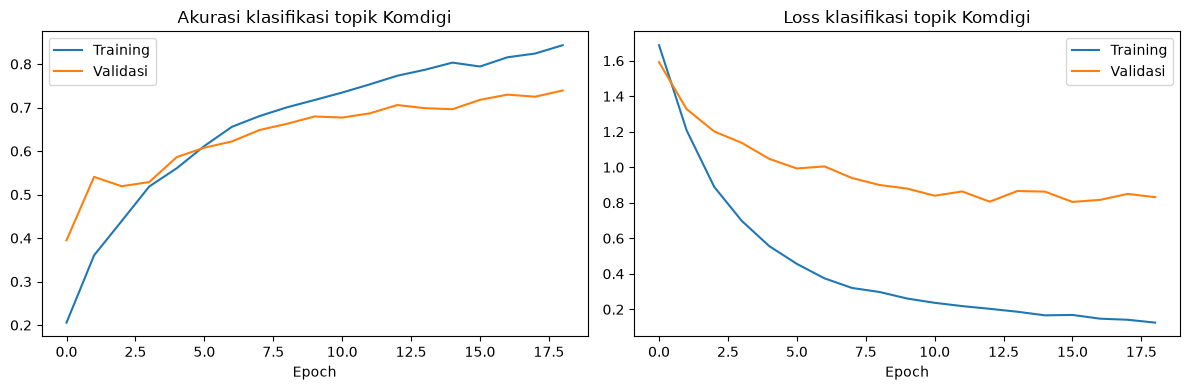

In [8]:
# Grafik akurasi dan loss selama pelatihan
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validasi")
axes[0].set_title("Akurasi klasifikasi topik Komdigi")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validasi")
axes[1].set_title("Loss klasifikasi topik Komdigi")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

In [9]:
# Contoh prediksi untuk artikel pertama pada data tes
sample_index = 0
print("Judul artikel:", X_test_text.iloc[sample_index][:200])
print("Topik aktual  :", label_encoder.inverse_transform([y_test[sample_index]])[0])
print("Topik prediksi:", label_encoder.inverse_transform([y_pred[sample_index]])[0])

Judul artikel: [HOAKS] Abu Janda Jadi Komisaris Jasa Marga Penjelasan : Beredar di media sosial X atau Twitter sebuah unggahan poster yang menyebut Permadi Arya, yang lebih dikenal publik sebagai "Abu Janda", telah 
Topik aktual  : Hoaks
Topik prediksi: Hoaks
